# Backtested VaR and Expected Shortfall — demo

This notebook **reads** the tables written by `scripts/run_results.py` (it does not
re-run the 20-year backtest, which takes several minutes) and shows how to call the
package on the latest date. It runs end to end in well under two minutes.

Portfolio: SPY 30 %, TLT 20 %, GLD 25 %, EEM 15 %, LQD 10 %, rebalanced daily.
Out-of-sample one-day forecasts from November 2006 to December 2025.

In [1]:
import json
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

t0 = time.perf_counter()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RES, FIG = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
json.loads((RES / "data_summary.json").read_text())

{'first_return_date': '2004-11-19',
 'last_date': '2025-12-31',
 'n_returns': 5312,
 'first_forecast_date': '2006-11-14',
 'annualised_mean_simple': 0.09398189555745538,
 'annualised_vol': 0.10987157535212672,
 'worst_day': '2020-03-12',
 'worst_day_return': -0.05722386613362141,
 'full_sample_t_nu': 3.454725726772871,
 'full_sample_garch_alpha_plus_beta': 0.9820152220024938,
 'full_sample_garch_half_life_days': 38.193147465814846,
 'spy_tlt_corr_250d_mean_2007_2021': -0.39466707814322116,
 'spy_tlt_corr_250d_end_2022': 0.08882157561351069}

## 1. Final table — method × level × exception rate × p-values × zone

Kupiec tests the number of exceptions, Christoffersen IND their independence, CC both.
Z2 (Acerbi–Székely) tests the 97.5 % Expected Shortfall. Zones: rolling 250-day Basel
traffic light (99 %), and the same binomial thresholds at 97.5 % (non-regulatory).

In [2]:
final = pd.read_csv(RES / "final_table.csv")
final

,model,level,T,N,expected,rate,p_uc,p_ind,p_cc,worst_zone,share_red,share_yellow,Z2,p_Z2
0,Historical,0.990,4812,50,48.12,0.0104,7.8666e-01,1.3860e-04,6.7718e-04,red,0.0217,0.2064,NaN,NaN
1,Historical,0.975,4812,124,120.30,0.0258,7.3389e-01,8.0861e-08,5.2955e-07,red,0.0723,0.1135,-0.1232,0.0602
2,Normal,0.990,4812,85,48.12,0.0177,1.4237e-06,1.9537e-07,1.1704e-11,red,0.0951,0.3331,NaN,NaN
3,Normal,0.975,4812,150,120.30,0.0312,8.2315e-03,4.7109e-09,1.0758e-09,red,0.0590,0.2018,-0.5722,0.0002
4,Student-t,0.990,4812,69,48.12,0.0143,4.5053e-03,3.9950e-07,4.6362e-08,red,0.0923,0.2465,NaN,NaN
5,Student-t,0.975,4812,149,120.30,0.0310,1.0575e-02,1.2009e-07,3.1177e-08,red,0.0776,0.1775,-0.3933,0.0012
6,FHS-GARCH,0.990,4812,46,48.12,0.0096,7.5700e-01,5.8917e-05,2.9872e-04,yellow,0.0000,0.0651,NaN,NaN
7,FHS-GARCH,0.975,4812,121,120.30,0.0251,9.4851e-01,1.4479e-02,5.0207e-02,yellow,0.0000,0.0526,-0.0457,0.2192
8,Monte Carlo,0.990,4812,73,48.12,0.0152,8.1036e-04,1.1610e-05,2.4376e-07,red,0.0831,0.2744,NaN,NaN
9,Monte Carlo,0.975,4812,168,120.30,0.0349,3.1879e-05,6.2893e-08,7.6215e-11,red,0.1175,0.1729,-0.4826,0.0002


## 2. Why models fail: number of exceptions or their clustering?

`LR_cc = LR_uc + LR_ind` (exactly, on the T−1 transitions). `ind_share` is the part of
the conditional-coverage statistic due to clustering. `pi11` is the probability of an
exception the day after an exception; under independence it equals `pi01`.

In [3]:
cov = pd.read_csv(RES / "coverage_tests.csv")
cov[["model", "level", "N", "expected", "LR_uc", "LR_ind", "LR_cc", "ind_share", "pi01", "pi11"]]

,model,level,N,expected,LR_uc,LR_ind,LR_cc,ind_share,pi01,pi11
0,Historical,0.990,50,48.12,0.0733,14.5211,14.5951,0.9949,0.0095,0.1000
1,Historical,0.975,124,120.30,0.1156,28.7853,28.9025,0.9959,0.0230,0.1290
2,Normal,0.990,85,48.12,23.2483,27.0784,50.3422,0.5379,0.0157,0.1294
3,Normal,0.975,150,120.30,6.9824,34.3053,41.3005,0.8306,0.0277,0.1400
4,Student-t,0.990,69,48.12,8.0680,25.6968,33.7736,0.7609,0.0127,0.1304
5,Student-t,0.975,149,120.30,6.5353,28.0196,34.5672,0.8106,0.0279,0.1275
6,FHS-GARCH,0.990,46,48.12,0.0957,16.1372,16.2320,0.9942,0.0086,0.1087
7,FHS-GARCH,0.975,121,120.30,0.0042,5.9787,5.9832,0.9993,0.0241,0.0661
8,Monte Carlo,0.990,73,48.12,11.2174,19.2264,30.4542,0.6313,0.0137,0.1096
9,Monte Carlo,0.975,168,120.30,17.3023,29.2721,46.5949,0.6282,0.0314,0.1310


In [4]:
clus = pd.read_csv(RES / "clustering.csv")
clus.pivot(index="model", columns="level", values="share_within").assign(
    iid_99=clus.loc[clus.level == 0.99, "iid_share"].iloc[0],
    iid_975=clus.loc[clus.level == 0.975, "iid_share"].iloc[0],
)

level,0.975,0.99,iid_99,iid_975
model,,,,
FHS-GARCH,0.2250,0.2000,0.0956,0.2237
Historical,0.4553,0.4286,0.0956,0.2237
Monte Carlo,0.5329,0.4444,0.0956,0.2237
Normal,0.5235,0.4881,0.0956,0.2237
Student-t,0.5203,0.4706,0.0956,0.2237


## 3. Exceptions per year (99 % VaR)

A model can be right *on average* over 19 years and wrong almost every year: excess
exceptions in a crisis are offset by years with none, while the estimation window is
still full of crisis losses.

In [5]:
pd.read_csv(RES / "exceptions_by_year_99.csv", index_col="year")

,T,expected,Historical,Normal,Student-t,FHS-GARCH,Monte Carlo
year,,,,,,,
2006,32,0.32,0,0,0,0,0
2007,251,2.51,5,6,6,4,6
2008,253,2.53,11,19,16,2,16
2009,252,2.52,0,0,0,0,0
2010,252,2.52,0,0,0,4,0
2011,252,2.52,5,7,5,3,5
2012,250,2.50,1,2,1,2,1
2013,252,2.52,2,3,2,3,2
2014,252,2.52,0,1,0,2,1


## 4. Crisis windows: counts, clustering, severity and the ES test

In [6]:
crisis = pd.read_csv(RES / "crisis_breakdown.csv")
crisis[crisis.level == 0.99][["period", "model", "T", "N", "expected", "consecutive_pairs",
                               "mean_loss_over_var_on_hits", "peak_rolling_count", "worst_zone"]]

,period,model,T,N,expected,consecutive_pairs,mean_loss_over_var_on_hits,peak_rolling_count,worst_zone
0,GFC Sep 2008 - Mar 2009,Historical,146,9,1.46,1,1.4371,11,red
1,COVID Feb - Apr 2020,Historical,62,7,0.62,1,2.6340,7,yellow
2,Rates shock 2022,Historical,251,3,2.51,0,1.6377,3,green
3,GFC Sep 2008 - Mar 2009,Normal,146,17,1.46,3,1.5821,19,red
4,COVID Feb - Apr 2020,Normal,62,9,0.62,2,2.5637,9,yellow
5,Rates shock 2022,Normal,251,8,2.51,0,1.3513,8,yellow
6,GFC Sep 2008 - Mar 2009,Student-t,146,14,1.46,3,1.6169,16,red
7,COVID Feb - Apr 2020,Student-t,62,9,0.62,2,2.7166,9,yellow
8,Rates shock 2022,Student-t,251,5,2.51,0,1.4019,5,yellow
9,GFC Sep 2008 - Mar 2009,FHS-GARCH,146,2,1.46,0,1.0372,2,green


In [7]:
es = pd.read_csv(RES / "es_backtest.csv")
es.pivot(index="model", columns="period", values="p_value")

period,COVID Feb - Apr 2020,Full sample,GFC Sep 2008 - Mar 2009,Rates shock 2022
model,,,,
FHS-GARCH,0.0002,0.2192,0.2801,0.6895
Historical,0.0002,0.0602,0.0002,0.0164
Monte Carlo,0.0004,0.0002,0.0002,0.0024
Normal,0.0002,0.0002,0.0002,0.0004
Student-t,0.0002,0.0012,0.0004,0.0068


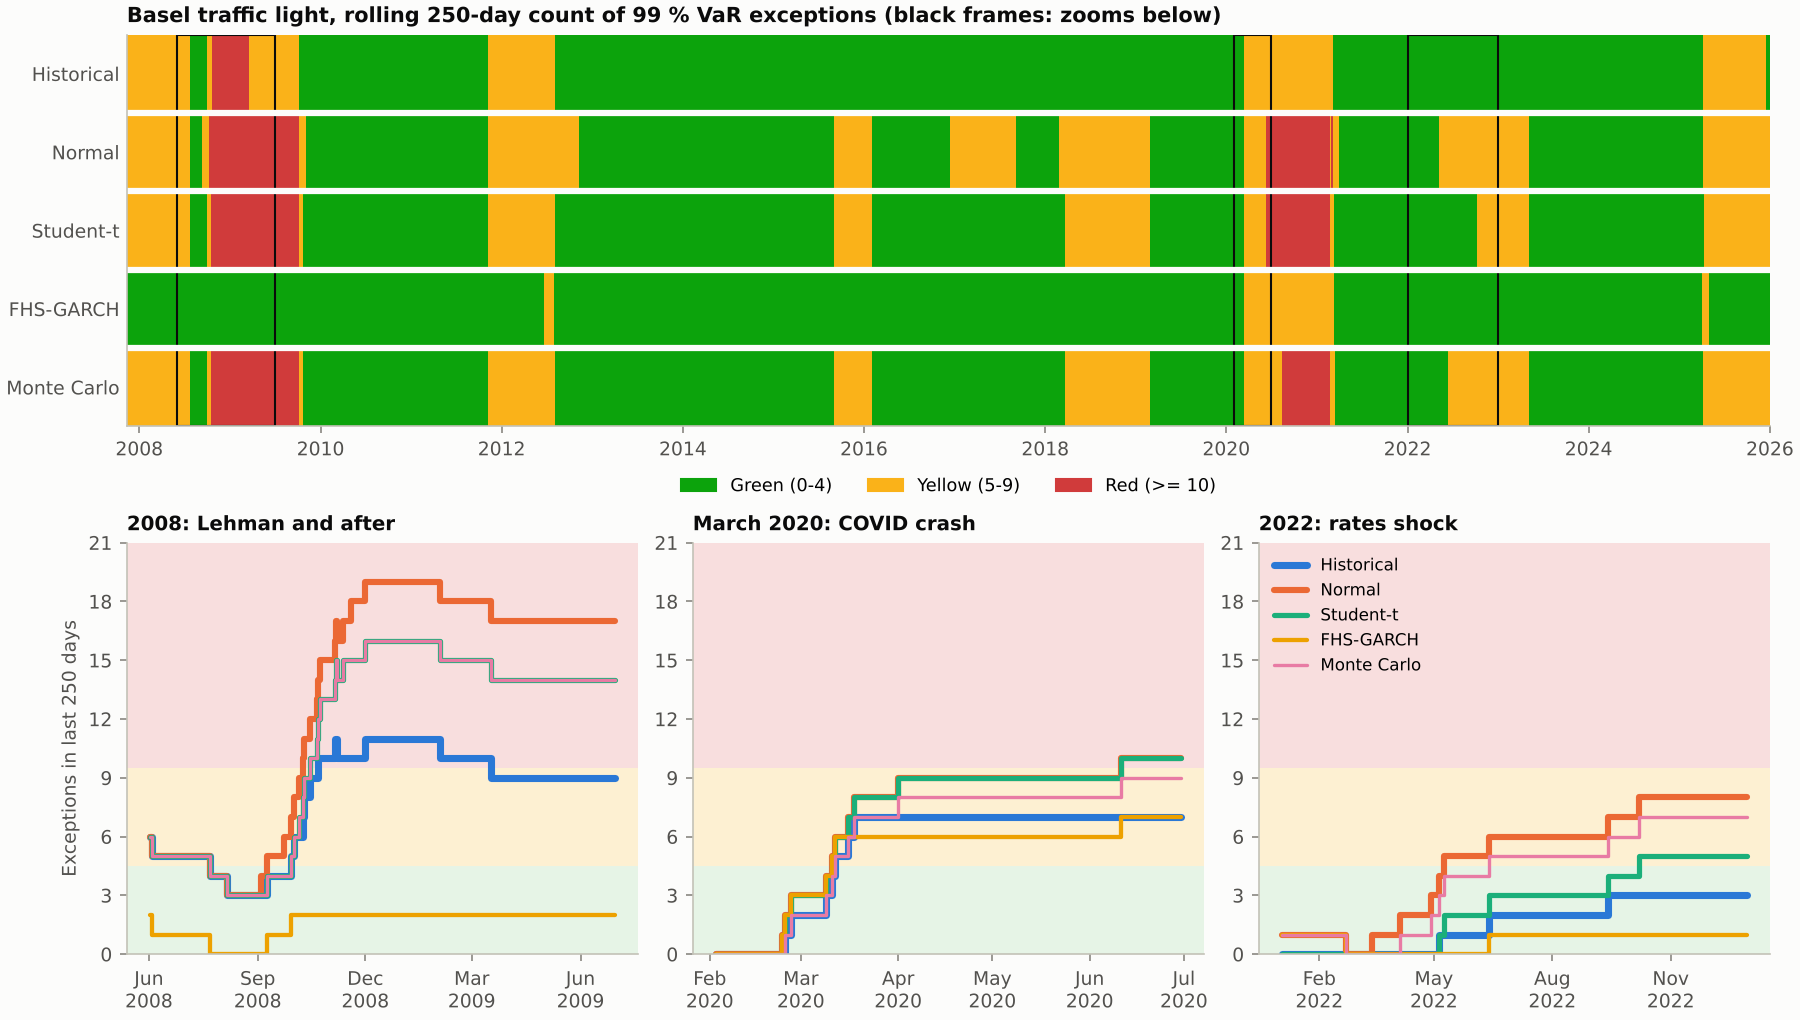

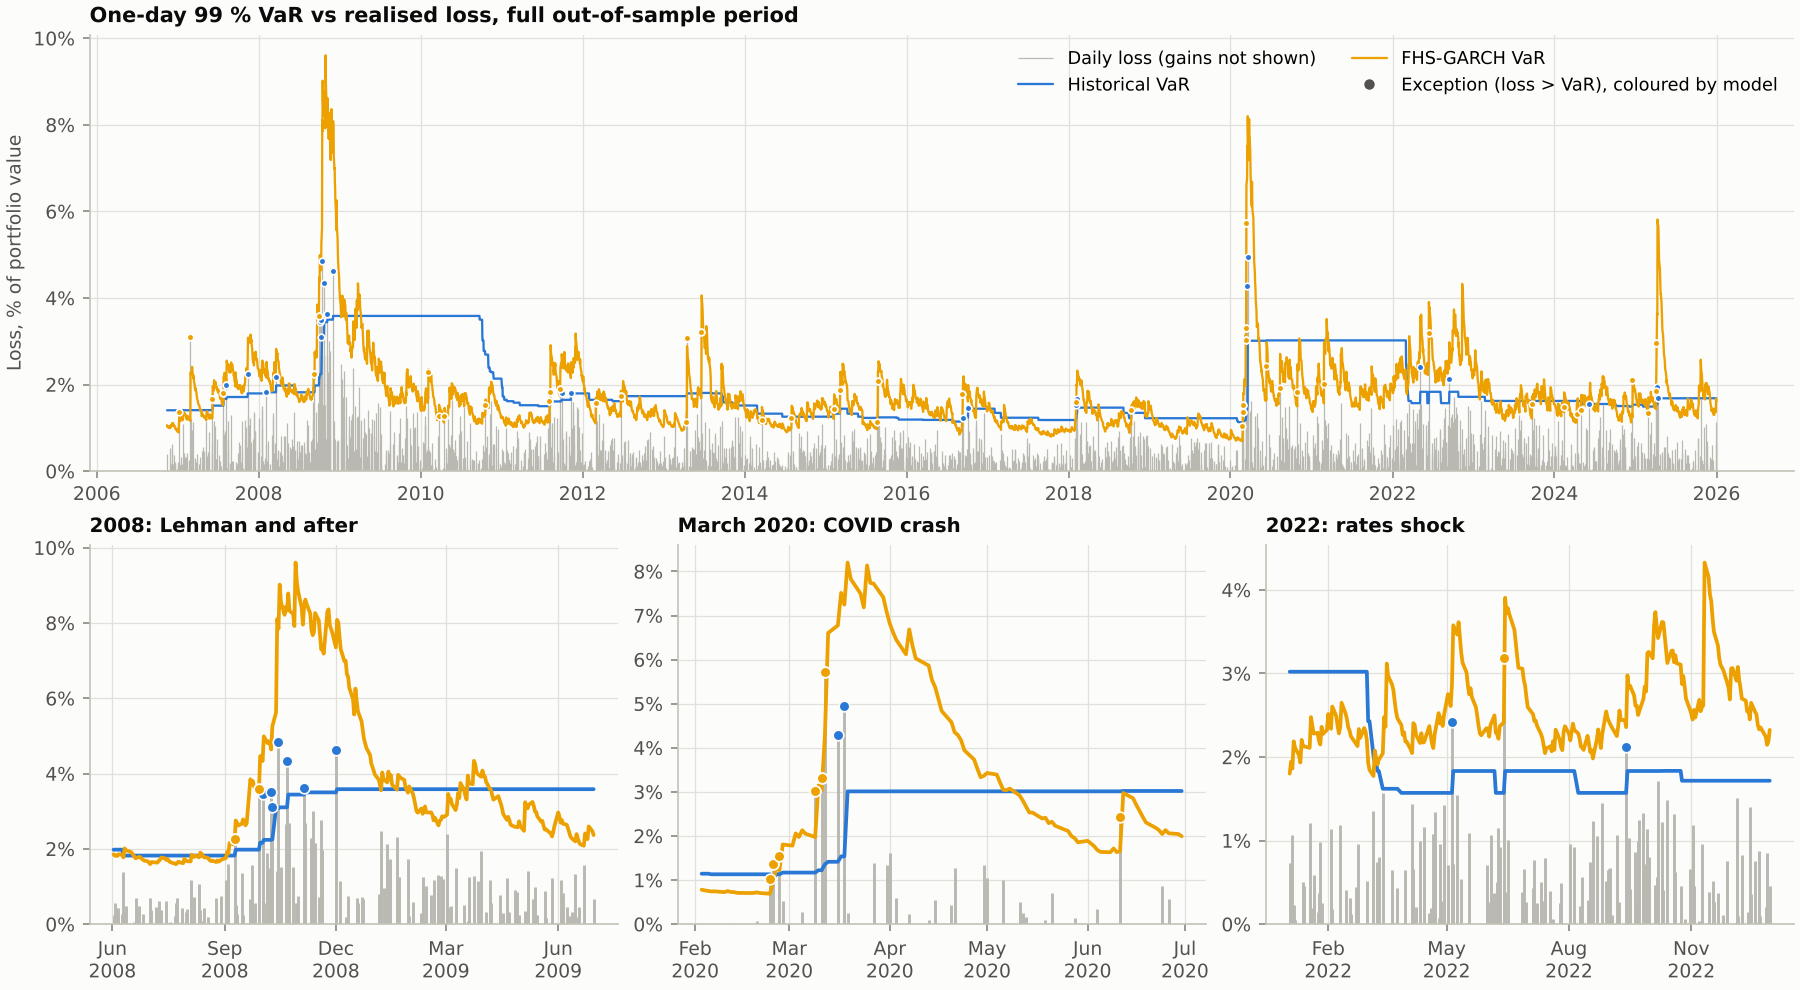

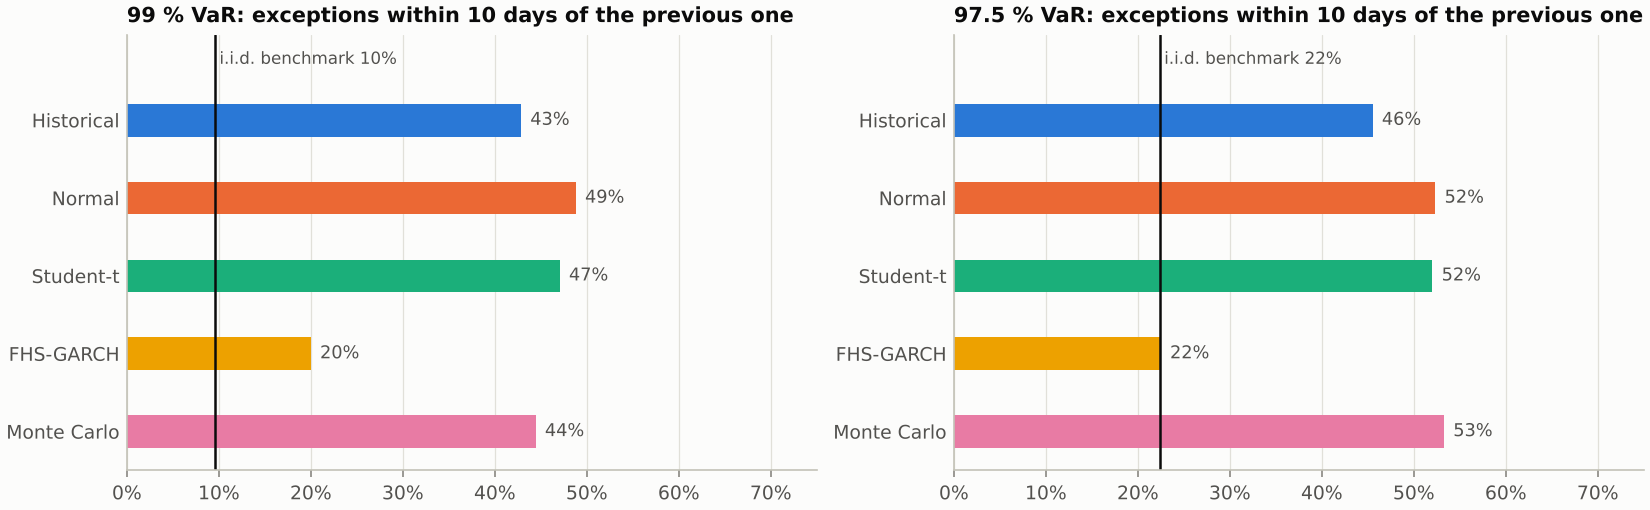

In [8]:
display(Image(FIG / "traffic_light.png"))
display(Image(FIG / "var_paths.png"))
display(Image(FIG / "clustering.png"))

## 5. Robustness: 250-day estimation window

Same study with W = 250 instead of 500.

In [9]:
pd.read_csv(RES / "sensitivity_window250.csv")[["model", "level", "N", "expected", "p_uc", "p_ind", "p_cc", "Z2", "p_Z2", "worst_zone", "share_red"]]

,model,level,N,expected,p_uc,p_ind,p_cc,Z2,p_Z2,worst_zone,share_red
0,Historical,0.990,59,50.62,2.4871e-01,5.2047e-05,1.4296e-04,NaN,NaN,yellow,0.0000
1,Historical,0.975,136,126.55,4.0049e-01,1.6133e-05,6.4125e-05,-0.2197,0.0026,red,0.0019
2,Normal,0.990,101,50.62,3.6634e-10,5.8747e-07,1.1134e-14,NaN,NaN,red,0.1199
3,Normal,0.975,174,126.55,5.2184e-05,9.4974e-08,1.8144e-10,-0.7170,0.0002,red,0.0970
4,Student-t,0.990,85,50.62,9.6062e-06,1.0463e-05,3.3529e-09,NaN,NaN,red,0.0573
5,Student-t,0.975,177,126.55,1.8011e-05,7.9187e-07,5.1162e-10,-0.5936,0.0004,red,0.0873
6,FHS-GARCH,0.990,49,50.62,8.1804e-01,1.1731e-03,5.0302e-03,NaN,NaN,yellow,0.0000
7,FHS-GARCH,0.975,127,126.55,9.6770e-01,1.5501e-03,6.6713e-03,-0.0838,0.1106,yellow,0.0000
8,Monte Carlo,0.990,88,50.62,1.7554e-06,2.4653e-07,1.7925e-11,NaN,NaN,red,0.0592
9,Monte Carlo,0.975,187,126.55,3.6338e-07,1.2964e-06,1.9387e-11,-0.6673,0.0002,red,0.1010


## 6. Using the package: tomorrow's VaR and ES after the last date of the sample

Each model is fitted on the data available at the close of 2025-12-31 only.

In [10]:
from var_es.config import DEFAULT
from var_es.data import load_prices, simple_returns
from var_es.models import build_models

R = simple_returns(load_prices(ROOT / "data", DEFAULT.tickers))  # SHA-256 checked
history = R.to_numpy()
rows = []
for model in build_models(DEFAULT):
    pred = model.predict(history, model.fit(history))
    rows.append({"model": model.name,
                 **{f"VaR {100 * lv:g} %": pred.var(lv) for lv in DEFAULT.levels},
                 **{f"ES {100 * lv:g} %": pred.es(lv) for lv in DEFAULT.levels}})
pd.DataFrame(rows).set_index("model").style.format("{:.2%}")

,VaR 99 %,VaR 97.5 %,ES 99 %,ES 97.5 %
model,,,,
Historical,1.68%,1.29%,2.11%,1.72%
Normal,1.38%,1.15%,1.60%,1.39%
Student-t,1.52%,1.12%,2.09%,1.61%
FHS-GARCH,1.65%,1.23%,2.04%,1.67%
Monte Carlo,1.42%,1.07%,1.99%,1.52%


In [11]:
print(f"notebook ran in {time.perf_counter() - t0:.1f} s")

notebook ran in 1.6 s
